# Trees and Model Stability

Trees are notorious for being **unstable**: Small changes in the data can lead to noticeable or large changes in the tree. We're going to explore this phenomenon.

1. Check out the data set `heart_failure` and appropriately clean it.
2. Perform a train-test split for a specific seed (save the seed for reproducibility). Fit a tree and a linear model on the training data and evaluate their performance on the test data. Set aside the predictions these models make.
3. Repeat step 2 for three to five different seeds (save the seeds for reproducibility). How different are the trees that you get? Your linear model coefficients?. Set aside the predictions these models make.
4. Typically, you would see the trees changing what appears to be a non-trivial amount, while the linear model coefficients don't vary nearly as much. Often, the changes appear substantial. 
But are they? Instead of focusing on the tree or model coefficients, do three things:
    
    a. Make scatterplots of the predicted values on the test set from question 2 against the predicted values for the alternative models from part 3, separately for your trees and linear models. Do they appear reasonably similar?
    
    b. Compute the correlation between your model in part 2 and your alternative models in part 3, separately for your trees and linear models. Are they highly correlated or not?
    
    c. Run a simple linear regression of the predicted values on the test set from the alternative models on the predicted values from question 2, separately for your trees and linear models. Is the intercept close to zero? Is the slope close to 1? Is the $R^2$ close to 1?

5. Do linear models appear to have similar coefficients and predictions across train/test splits? Do trees?
6. True or false for this dataset, and explain: "Even if the models end up having a substantially different appearance, the predictions they generate are often very similar."

---

## *Phase 1: Solution without AI

Complete all questions in the following cells without generative AI. Then commit and push the
notebook before beginning Phase 2.

**Declaration:** I completed this version without generative AI.

**Student(s):** Aiden Zhu, Anaya Green, Noah Weinstein

**Date:** 11/18/2026


[notice] A new release of pip is available: 25.3 -> 26.3
[notice] To update, run: pip install --upgrade pip
Note: you may need to restart the kernel to use updated packages.
(299, 13) 

age                         float64
anaemia                       int64
creatinine_phosphokinase      int64
diabetes                      int64
ejection_fraction             int64
high_blood_pressure           int64
platelets                   float64
serum_creatinine            float64
serum_sodium                  int64
sex                           int64
smoking                       int64
time                          int64
DEATH_EVENT                   int64
dtype: object 

              age     anaemia  creatinine_phosphokinase    diabetes  \
count  299.000000  299.000000                299.000000  299.000000   
mean    60.833893    0.431438                581.839465    0.418060   
std     11.894809    0.496107                970.287881    0.494067   
min     40.000000    0.000000                

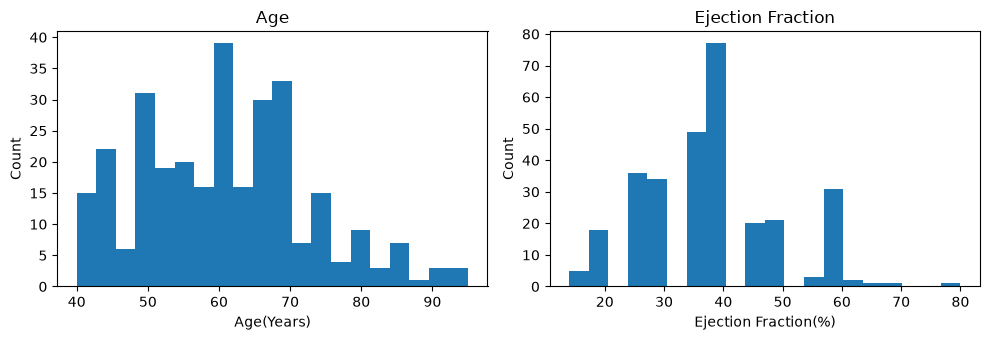

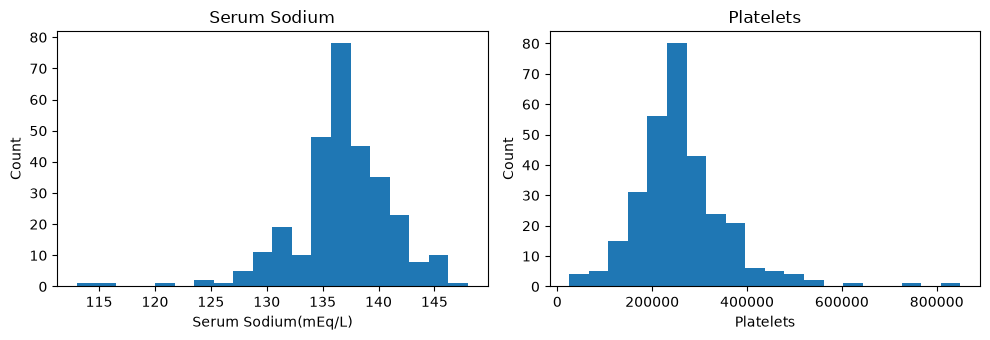

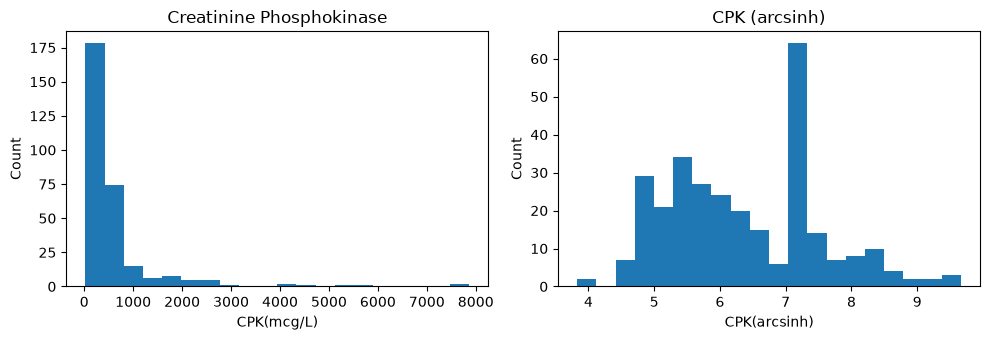

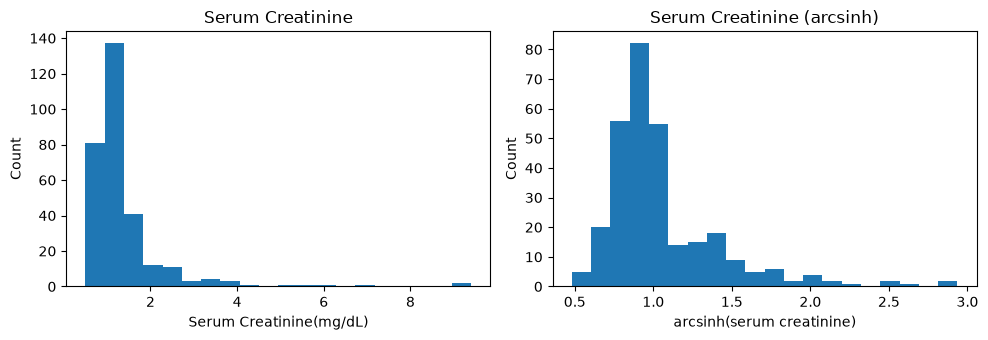

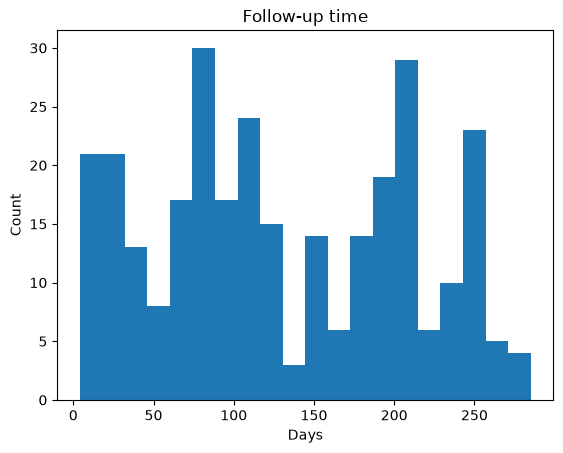

224 training patients; 75 test patients
Tree accuracy: 0.693


Predicted,0,1
Actual,,
0,45,6
1,17,7


Logistic accuracy: 0.667
Test BCE: 0.532


/workspaces/L03-tree-stability/.venv/lib/python3.14/site-packages/sklearn/linear_model/_logistic.py:599: ConvergenceWarning: lbfgs failed to converge after 1000 iteration(s) (status=1):
STOP: TOTAL NO. OF ITERATIONS REACHED LIMIT

Increase the number of iterations to improve the convergence (max_iter=1000).
You might also want to scale the data as shown in:
    https://scikit-learn.org/stable/modules/preprocessing.html
Please also refer to the documentation for alternative solver options:
    https://scikit-learn.org/stable/modules/linear_model.html#logistic-regression
  n_iter_i = _check_optimize_result(


Predicted,0,1
Actual,,
0,43,8
1,17,7


Seed 100


... (14 outputs left out)

/workspaces/L03-tree-stability/.venv/lib/python3.14/site-packages/sklearn/linear_model/_logistic.py:599: ConvergenceWarning: lbfgs failed to converge after 1000 iteration(s) (status=1):
STOP: TOTAL NO. OF ITERATIONS REACHED LIMIT

Increase the number of iterations to improve the convergence (max_iter=1000).
You might also want to scale the data as shown in:
    https://scikit-learn.org/stable/modules/preprocessing.html
Please also refer to the documentation for alternative solver options:
    https://scikit-learn.org/stable/modules/linear_model.html#logistic-regression
  n_iter_i = _check_optimize_result(


Predicted,0,1
Actual,,
0,39,12
1,10,14


Predicted,0,1
Actual,,
0,43,8
1,13,11


,age,anaemia,creatinine_phosphokinase,diabetes,ejection_fraction,high_blood_pressure,platelets,serum_creatinine,serum_sodium,sex,smoking
100,0.0581,0.3183,0.0003,0.1327,-0.0776,0.4443,0.0,0.6016,-0.0218,-0.0373,-0.3755
1,0.0476,0.4166,0.0003,-0.2001,-0.1011,0.1682,-0.0,0.7222,-0.0050,-0.9109,0.1299
2,0.0551,0.3341,0.0003,0.2361,-0.0673,0.3566,0.0,0.7725,-0.0248,-0.4096,0.1755
3,0.0605,0.5656,0.0004,0.2636,-0.0616,0.0768,-0.0,0.6209,-0.0250,-0.3466,0.2108
4,0.0523,0.3849,0.0003,0.3974,-0.0741,0.3425,-0.0,0.8683,-0.0195,-0.6256,0.3402


In [19]:
# Your Phase 1 solution to the problem goes here.
%pip install scikit-learn
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split
from sklearn.tree import DecisionTreeClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import log_loss


df = pd.read_csv("data/heart_failure/heart_failure_clinical_records_dataset.csv")

print(df.shape, "\n")
print(df.dtypes, "\n")
print(df.describe(), "\n")
print(df.isnull().sum(), "\n")
df.value_counts()

fig, axes = plt.subplots(1, 2, figsize=(10, 3.5))
df["age"].hist(bins=20, grid=False, ax=axes[0])
axes[0].set(title="Age", xlabel="Age(Years)", ylabel="Count")
df["ejection_fraction"].hist(bins=20, grid=False, ax=axes[1])
axes[1].set(title="Ejection Fraction", xlabel="Ejection Fraction(%)", ylabel="Count")
plt.tight_layout()
plt.show()

fig, axes = plt.subplots(1, 2, figsize=(10, 3.5))
df["serum_sodium"].hist(bins=20, grid=False, ax=axes[0])
axes[0].set(title="Serum Sodium", xlabel="Serum Sodium(mEq/L)", ylabel="Count")
df["platelets"].hist(bins=20, grid=False, ax=axes[1])
axes[1].set(title="Platelets", xlabel="Platelets", ylabel="Count")
plt.tight_layout()
plt.show()

df["cpk_arcsinh"] = np.arcsinh(df["creatinine_phosphokinase"])
df["creatinine_arcsinh"] = np.arcsinh(df["serum_creatinine"])

fig, axes = plt.subplots(1, 2, figsize=(10, 3.5))
df["creatinine_phosphokinase"].hist(bins=20, grid=False, ax=axes[0])
axes[0].set(title="Creatinine Phosphokinase", xlabel="CPK(mcg/L)", ylabel="Count")
df["cpk_arcsinh"].hist(bins=20, grid=False, ax=axes[1])
axes[1].set(title="CPK (arcsinh)", xlabel="CPK(arcsinh)", ylabel="Count")
plt.tight_layout()
plt.show()

fig, axes = plt.subplots(1, 2, figsize=(10, 3.5))
df["serum_creatinine"].hist(bins=20, grid=False, ax=axes[0])
axes[0].set(title="Serum Creatinine", xlabel="Serum Creatinine(mg/dL)", ylabel="Count")
df["creatinine_arcsinh"].hist(bins=20, grid=False, ax=axes[1])
axes[1].set(title="Serum Creatinine (arcsinh)", xlabel="arcsinh(serum creatinine)", ylabel="Count")
plt.tight_layout()
plt.show()

df["time"].hist(bins=20, grid=False)
plt.title("Follow-up time")
plt.xlabel("Days")
plt.ylabel("Count")
plt.show()

seed = 100

features = [
    "age", "anaemia", "creatinine_phosphokinase", "diabetes",
    "ejection_fraction", "high_blood_pressure", "platelets",
    "serum_creatinine", "serum_sodium", "sex", "smoking"
]
X = df[features]
y = df["DEATH_EVENT"]

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.25, random_state=seed, stratify=y
)
print(len(X_train), "training patients;", len(X_test), "test patients")

tree = DecisionTreeClassifier(max_depth=3, random_state=seed).fit(
    X_train, y_train
)
p_tree = tree.predict_proba(X_test)[:, 1]
y_hat_tree = tree.predict(X_test)
print("Tree accuracy:", round(np.sum(y_hat_tree == y_test) / len(y_test), 3))
display(pd.crosstab(y_test, y_hat_tree,
            rownames=["Actual"], colnames=["Predicted"]))

model = LogisticRegression(C=np.inf, max_iter=1000, tol=1e-8)
model.fit(X_train, y_train);
p_test = model.predict_proba(X_test)[:, 1]
predicted = model.predict(X_test)
print("Logistic accuracy:", round(np.sum(predicted == y_test) / len(y_test), 3))
print(f"Test BCE: {log_loss(y_test, p_test):.3f}")
display(pd.crosstab(y_test, predicted,
            rownames=["Actual"], colnames=["Predicted"]))

predictions = pd.DataFrame({
    "actual": y_test,
    "tree": p_tree,
    "logistic": p_test,
})
predictions.head()

seeds = [seed, 1, 2, 3, 4]
tree_models = []
logistic_models = []

for s in seeds:
    X_train_s, X_test_s, y_train_s, y_test_s = train_test_split(
        X, y, test_size=0.25, random_state=s, stratify=y
    )
    tree_s = DecisionTreeClassifier(max_depth=3, random_state=s).fit(
        X_train_s, y_train_s
    )
    model_s = LogisticRegression(C=np.inf, max_iter=1000, tol=1e-8)
    model_s.fit(X_train_s, y_train_s);
    tree_models.append(tree_s)
    logistic_models.append(model_s)

    print(f"Seed {s}")
    display(pd.crosstab(y_test_s, tree_s.predict(X_test_s),
                rownames=["Actual"], colnames=["Predicted"]))
    display(pd.crosstab(y_test_s, model_s.predict(X_test_s),
                rownames=["Actual"], colnames=["Predicted"]))

coefficients = np.array([fit.coef_[0] for fit in logistic_models])
display(pd.DataFrame(coefficients, columns=features, index=seeds).round(4))

tree_predictions = np.array([fit.predict_proba(X_test)[:, 1] for fit in tree_models])
logistic_predictions = np.array([fit.predict_proba(X_test)[:, 1] for fit in logistic_models])


## *Phase 2: AI-assisted Revision
Keep Phase 1 frozen.

- **Phase 1 commit SHA ID:** [To be provided]
- **AI tool and model used:** [To be provided]

### *Prompts used

1. [Paste prompt]
2. [Paste follow-up prompt]

### *AI-proposed changes


[Paste the AI's concise numbered list verbatim.]

1. ...
2. ...

### *Evaluation of AI suggestions


| Change | Decision | Reason and verification |
|---|---|---|
| 1 | Accept / modify / reject | ... |
| 2 | Accept / modify / reject | ... |

### *AI-assisted solution in full
After the evaluation of AI suggestions, incorporate the accepted revisions into your Phase 1 solution and provide the final Phase 2 solution in full in the following cells.

In [ ]:
# Your Phase 2 solution to the problem goes here.


### *Reflection on AI assistance
In your own words without generative AI.

[In 150–300 words, describe the main improvements, AI mistakes or limitations, how the final solution was verified, and any remaining concerns.]